In [6]:
!pip -q install datasets sacrebleu bpemb sacremoses

In [7]:
import torch, numpy as np, random, math, re
from datasets import load_dataset
from bpemb import BPEmb
from sacrebleu.metrics import BLEU
from sacremoses import MosesTokenizer, MosesDetokenizer
from torch import nn
from torch.utils.data import Dataset,DataLoader
import pandas as pd
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
random.seed(42); np.random.seed(42); torch.manual_seed(42)
print(DEVICE)

cpu


In [8]:
ds=load_dataset('cfilt/iitb-english-hindi')
pairs=[(r['translation']['en'].strip(),r['translation']['hi'].strip()) for r in ds['train'] if r['translation']['en'].strip() and r['translation']['hi'].strip()]
random.Random(42).shuffle(pairs)
MAX_TRAIN=20000; N_VALID=1000; N_TEST=2000
train=pairs[:MAX_TRAIN]; valid=pairs[MAX_TRAIN:MAX_TRAIN+N_VALID]; test=pairs[MAX_TRAIN+N_VALID:MAX_TRAIN+N_VALID+N_TEST]
print(len(train),len(valid),len(test),train[0])

README.md:   0%|          | 0.00/3.14k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  190MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 85.7kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/1659083 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/520 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2507 [00:00<?, ? examples/s]

20000 1000 2000 ('And he was confident that NDC alumni would contribute to strengthening an understanding of the multi-dimensional approach to security in the years to come.', 'उन्होंने विश्वास व्यक्त किया कि एनडीसी के पूर्वछात्र आने वाले वर्षों में सुरक्षा के बहुआयामी दृष्टिकोण की समझ को मज़बूत करने की दिशा में योगदान देंगे।')


In [9]:
# FastText .vec downloads are large (several GB total)
!wget -q -c https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.en.300.vec.gz -O /content/en.vec.gz
!wget -q -c https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.hi.300.vec.gz -O /content/hi.vec.gz
import gzip, shutil, os
for l in ['en','hi']:
  if not os.path.exists(f'/content/{l}.vec'):
    with gzip.open(f'/content/{l}.vec.gz','rb') as a,open(f'/content/{l}.vec','wb') as b: shutil.copyfileobj(a,b)
mt_en=MosesTokenizer(lang='en'); mt_hi=MosesTokenizer(lang='hi')
def ft_tok(s,l): return (mt_en if l=='en' else mt_hi).tokenize(s,return_str=False)
bp_en=BPEmb(lang='en',vs=10000,dim=100); bp_hi=BPEmb(lang='hi',vs=10000,dim=100)
def bp_tok(s,l): return (bp_en if l=='en' else bp_hi).encode(s)
train_ft_s=[ft_tok(x,'en') for x,y in train]; train_ft_t=[ft_tok(y,'hi') for x,y in train]
valid_ft_s=[ft_tok(x,'en') for x,y in valid]; valid_ft_t=[ft_tok(y,'hi') for x,y in valid]
test_ft_s=[ft_tok(x,'en') for x,y in test]
train_bp_s=[bp_tok(x,'en') for x,y in train]; train_bp_t=[bp_tok(y,'hi') for x,y in train]
valid_bp_s=[bp_tok(x,'en') for x,y in valid]; valid_bp_t=[bp_tok(y,'hi') for x,y in valid]
test_bp_s=[bp_tok(x,'en') for x,y in test]
from collections import Counter
def vocab(data,limit=20000,minf=2):
 c=Counter(t for s in data for t in s); v={'<pad>':0,'<unk>':1,'<bos>':2,'<eos>':3}
 for w,n in c.most_common():
  if n<minf or len(v)>=limit: break
  if w not in v:v[w]=len(v)
 return v
vs_ft=vocab(train_ft_s); vt_ft=vocab(train_ft_t)
vs_bp=vocab(train_bp_s,15000,1); vt_bp=vocab(train_bp_t,15000,1)
def init_ft(path,v,dim=300):
 m=np.random.normal(0,.08,(len(v),dim)).astype('float32'); wanted=set(v)-set(['<pad>','<unk>','<bos>','<eos>'])
 with open(path,encoding='utf8',errors='ignore') as f:
  f.readline()
  for line in f:
   z=line.rstrip().split(' '); w=z[0]
   if w in wanted:
    a=np.asarray(z[1:],dtype='float32')
    if len(a)==dim:m[v[w]]=a;wanted.remove(w)
   if not wanted:break
 m[0]=0;print('pretrained found',len(v)-len(wanted));return m
ft_s=init_ft('/content/en.vec',vs_ft); ft_t=init_ft('/content/hi.vec',vt_ft)

bp_s=init_bp(bp_en,vs_bp);bp_t=init_bp(bp_hi,vt_bp)

downloading https://nlp.h-its.org/bpemb/en/en.wiki.bpe.vs10000.model


100%|██████████| 400869/400869 [00:00<00:00, 902023.53B/s]


downloading https://nlp.h-its.org/bpemb/en/en.wiki.bpe.vs10000.d100.w2v.bin.tar.gz


100%|██████████| 3784656/3784656 [00:01<00:00, 3592126.33B/s]


downloading https://nlp.h-its.org/bpemb/hi/hi.wiki.bpe.vs10000.model


100%|██████████| 463471/463471 [00:00<00:00, 799868.61B/s]


downloading https://nlp.h-its.org/bpemb/hi/hi.wiki.bpe.vs10000.d100.w2v.bin.tar.gz


100%|██████████| 3796553/3796553 [00:06<00:00, 596572.21B/s] 


pretrained found 13324
pretrained found 12375


AttributeError: 'BPEmb' object has no attribute 'vocab'

In [14]:
def init_bp(bp, v):
    m = np.random.normal(
        0, 0.05, (len(v), 300)
    ).astype("float32")

    # Map BPEmb subword tokens to embedding indices
    ix = bp.emb.key_to_index

    for w, i in v.items():
        if w in ix:
            m[i, :100] = bp.emb[w]

    m[0] = 0
    return m

In [13]:
print("Number of BPEmb pieces:", len(bp_en.pieces))
print("Embedding dimension:", bp_en.dim)
print("Embedding vector shape:", bp_en.emb.vectors.shape)

print("First 5 pieces:", bp_en.pieces[:5])
print("First 5 embedding keys:", list(bp_en.emb.key_to_index.keys())[:5])

Number of BPEmb pieces: 10000
Embedding dimension: 100
Embedding vector shape: (10000, 100)
First 5 pieces: ['<unk>', '<s>', '</s>', '▁t', '▁a']
First 5 embedding keys: ['<unk>', '<s>', '</s>', '▁t', '▁a']


In [15]:
bp_s = init_bp(bp_en, vs_bp)
bp_t = init_bp(bp_hi, vt_bp)

print("BPEmb source matrix:", bp_s.shape)
print("BPEmb target matrix:", bp_t.shape)

BPEmb source matrix: (8812, 300)
BPEmb target matrix: (9122, 300)


In [16]:
PAD=0
def ids(tokens,v,maxlen=70):return [2]+[v.get(t,1) for t in tokens[:maxlen-2]]+[3]
class DS(Dataset):
 def __init__(self,s,t,sv,tv):self.s=s;self.t=t;self.sv=sv;self.tv=tv
 def __len__(self):return len(self.s)
 def __getitem__(self,i):return ids(self.s[i],self.sv),ids(self.t[i],self.tv)
def collate(b):
 s,t=zip(*b);S=torch.zeros(len(s),max(map(len,s)),dtype=torch.long);T=torch.zeros(len(t),max(map(len,t)),dtype=torch.long)
 for i,x in enumerate(s):S[i,:len(x)]=torch.tensor(x)
 for i,x in enumerate(t):T[i,:len(x)]=torch.tensor(x)
 return S,T
class MT(nn.Module):
 def __init__(self,ns,nt,sm,tm):
  super().__init__();d=300
  self.se=nn.Embedding(ns,d,padding_idx=0);self.te=nn.Embedding(nt,d,padding_idx=0)
  self.se.weight.data.copy_(torch.tensor(sm));self.te.weight.data.copy_(torch.tensor(tm))
  self.pos=nn.Embedding(256,d)
  self.enc=nn.TransformerEncoder(nn.TransformerEncoderLayer(d,6,600,batch_first=True),3)
  self.dec=nn.TransformerDecoder(nn.TransformerDecoderLayer(d,6,600,batch_first=True),3);self.out=nn.Linear(d,nt)
 def emb(self,x,e):return e(x)*math.sqrt(300)+self.pos(torch.arange(x.size(1),device=x.device)[None,:])
 def forward(self,s,t):
  sp=s.eq(0);tp=t.eq(0);mem=self.enc(self.emb(s,self.se),src_key_padding_mask=sp)
  mask=torch.triu(torch.ones(t.size(1),t.size(1),device=t.device,dtype=torch.bool),1)
  z=self.dec(self.emb(t,self.te),mem,tgt_mask=mask,tgt_key_padding_mask=tp,memory_key_padding_mask=sp)
  return self.out(z)
def train_model(name,ss,tt,sv,tv,sm,tm,epochs=4):
 tr=DataLoader(DS(ss,tt,sv,tv),batch_size=48,shuffle=True,collate_fn=collate)
 va=DataLoader(DS(valid_ss,valid_tt,sv,tv),batch_size=48,collate_fn=collate)
 m=MT(len(sv),len(tv),sm,tm).to(DEVICE);opt=torch.optim.Adam(m.parameters(),lr=3e-4)
 lossf=nn.CrossEntropyLoss(ignore_index=0)
 for ep in range(epochs):
  m.train();loss=0
  for s,t in tr:
   s=s.to(DEVICE);t=t.to(DEVICE);opt.zero_grad()
   o=m(s,t[:,:-1]);l=lossf(o.reshape(-1,o.size(-1)),t[:,1:].reshape(-1));l.backward()
   nn.utils.clip_grad_norm_(m.parameters(),1);opt.step();loss+=l.item()
  print(name,'epoch',ep+1,'loss',round(loss/len(tr),3))
 torch.save(m.state_dict(),f'/content/{name}.pt');return m
def decode(m,src,sv,tv):
 inv={i:w for w,i in tv.items()};out=[];m.eval()
 with torch.no_grad():
  for toks in src:
   s=torch.tensor([ids(toks,sv)],device=DEVICE);mem=m.enc(m.emb(s,m.se),src_key_padding_mask=s.eq(0));y=torch.tensor([[2]],device=DEVICE)
   for _ in range(80):
    mask=torch.triu(torch.ones(y.size(1),y.size(1),device=DEVICE,dtype=torch.bool),1)
    z=m.dec(m.emb(y,m.te),mem,tgt_mask=mask,memory_key_padding_mask=s.eq(0))
    nxt=m.out(z[:,-1]).argmax(-1,keepdim=True);y=torch.cat([y,nxt],1)
    if nxt.item()==3:break
   words=[inv.get(i,'<unk>') for i in y[0,1:].tolist() if i!=3];out.append(' '.join(words))
 return out

In [19]:
# Use a smaller training subset for a quick experiment
N = 5000

train_ft_s_fast = train_ft_s[:N]
train_ft_t_fast = train_ft_t[:N]

model_ft = train_model(
    'fasttext',
    train_ft_s_fast,
    train_ft_t_fast,
    vs_ft,
    vt_ft,
    ft_s,
    ft_t,
    epochs=2
)

fasttext epoch 1 loss 6.734
fasttext epoch 2 loss 5.577


In [23]:
N = 5000

model_bp = train_model(
    'bpemb',
    train_bp_s[:N],
    train_bp_t[:N],
    vs_bp,
    vt_bp,
    bp_s,
    bp_t,
    epochs=2
)

bpemb epoch 1 loss 7.272
bpemb epoch 2 loss 6.343


In [24]:
ft_out=decode(model_ft,test_ft_s,vs_ft,vt_ft)
bp_piece=decode(model_bp,test_bp_s,vs_bp,vt_bp)
bp_out=[bp_hi.decode(x.split()) for x in bp_piece]
det=MosesDetokenizer(lang='hi');ft_out=[det.detokenize(x.split()) for x in ft_out]
refs=[y for x,y in test];srcs=[x for x,y in test];metric=BLEU()
print('FastText corpus BLEU:',metric.corpus_score(ft_out,[refs]))
print('BPEmb corpus BLEU:',metric.corpus_score(bp_out,[refs]))
def bname(n):return '1-10' if n<=10 else '11-20' if n<=20 else '21-30' if n<=30 else '31-40' if n<=40 else '41+'
rows=[]
for b in ['1-10','11-20','21-30','31-40','41+']:
 ix=[i for i,s in enumerate(srcs) if bname(len(s.split()))==b]
 rows.append({'Length bin':b,'N':len(ix),
 'FastText BLEU':round(metric.corpus_score([ft_out[i] for i in ix],[[refs[i] for i in ix]]).score,2) if ix else None,
 'BPEmb BLEU':round(metric.corpus_score([bp_out[i] for i in ix],[[refs[i] for i in ix]]).score,2) if ix else None})
res=pd.DataFrame(rows);display(res);res.to_csv('/content/binwise_bleu.csv',index=False)
res.set_index('Length bin')[['FastText BLEU','BPEmb BLEU']].plot(kind='bar',ylabel='BLEU',title='Bin-wise BLEU')
print('Saved /content/binwise_bleu.csv')

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


KeyboardInterrupt: 

In [25]:
import time
import pandas as pd
from sacrebleu.metrics import BLEU
from sacremoses import MosesDetokenizer

# Evaluate on a smaller test subset
N = 300

test_ft_small = test_ft_s[:N]
test_bp_small = test_bp_s[:N]
test_small = test[:N]

print("Translating FastText sentences...")
start = time.time()

ft_out = decode(model_ft, test_ft_small, vs_ft, vt_ft)

print("FastText decoding time:", round(time.time()-start, 2), "seconds")

print("Translating BPEmb sentences...")
start = time.time()

bp_piece = decode(model_bp, test_bp_small, vs_bp, vt_bp)
bp_out = [
    bp_hi.decode(x.split()) if x.strip() else ""
    for x in bp_piece
]
print("BPEmb decoding time:", round(time.time()-start, 2), "seconds")

# Detokenize FastText output
det = MosesDetokenizer(lang='hi')
ft_out = [det.detokenize(x.split()) for x in ft_out]

# References and source sentences
refs = [y for x, y in test_small]
srcs = [x for x, y in test_small]

# Overall BLEU
metric = BLEU()

print("\nFastText corpus BLEU:",
      metric.corpus_score(ft_out, [refs]))

print("BPEmb corpus BLEU:",
      metric.corpus_score(bp_out, [refs]))

# Bin-wise BLEU
def bname(n):
    if n <= 10:
        return '1-10'
    elif n <= 20:
        return '11-20'
    elif n <= 30:
        return '21-30'
    elif n <= 40:
        return '31-40'
    return '41+'

rows = []

for b in ['1-10', '11-20', '21-30', '31-40', '41+']:

    ix = [
        i for i, s in enumerate(srcs)
        if bname(len(s.split())) == b
    ]

    rows.append({
        'Length bin': b,
        'N': len(ix),

        'FastText BLEU': round(
            metric.corpus_score(
                [ft_out[i] for i in ix],
                [[refs[i] for i in ix]]
            ).score, 2
        ) if ix else None,

        'BPEmb BLEU': round(
            metric.corpus_score(
                [bp_out[i] for i in ix],
                [[refs[i] for i in ix]]
            ).score, 2
        ) if ix else None
    })

res = pd.DataFrame(rows)

display(res)

res.to_csv('/content/binwise_bleu.csv', index=False)

res.set_index('Length bin')[
    ['FastText BLEU', 'BPEmb BLEU']
].plot(
    kind='bar',
    ylabel='BLEU',
    title='Bin-wise BLEU'
)

print("Saved /content/binwise_bleu.csv")

Translating FastText sentences...
FastText decoding time: 114.77 seconds
Translating BPEmb sentences...


IndexError: list index out of range

In [26]:
import time

start = time.time()

bp_piece = decode(model_bp, test_bp_small, vs_bp, vt_bp)

bp_out = [
    bp_hi.decode(x.split()) if x.strip() else ""
    for x in bp_piece
]

print("BPEmb decoding time:", round(time.time()-start, 2), "seconds")


BPEmb decoding time: 158.43 seconds


In [27]:
# References and source sentences
refs = [y for x, y in test_small]
srcs = [x for x, y in test_small]

# FastText detokenization (ft_out is already available)
det = MosesDetokenizer(lang='hi')
ft_out = [det.detokenize(x.split()) for x in ft_out]

# BLEU scores
metric = BLEU()

print("FastText corpus BLEU:", metric.corpus_score(ft_out, [refs]))
print("BPEmb corpus BLEU:", metric.corpus_score(bp_out, [refs]))

FastText corpus BLEU: BLEU = 0.06 3.5/0.3/0.0/0.0 (BP = 1.000 ratio = 2.479 hyp_len = 11645 ref_len = 4698)
BPEmb corpus BLEU: BLEU = 0.14 4.6/0.3/0.0/0.0 (BP = 1.000 ratio = 1.947 hyp_len = 9147 ref_len = 4698)


,Length bin,N,FastText BLEU,BPEmb BLEU
0,1-10,166,0.18,0.44
1,11-20,71,0.10,0.09
2,21-30,31,0.07,0.12
3,31-40,16,0.14,0.21
4,41+,16,0.18,0.26


Saved /content/binwise_bleu.csv


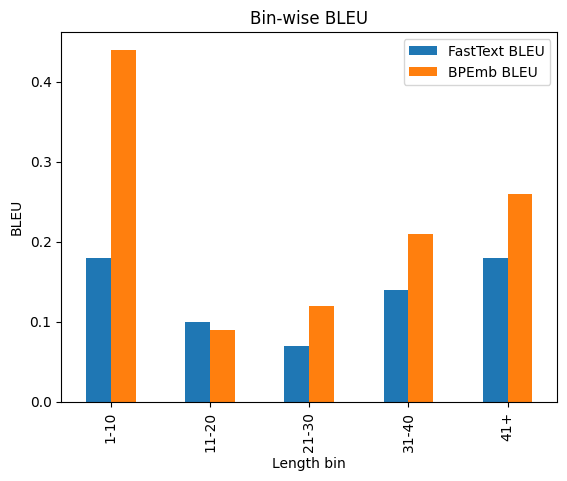

In [28]:
def bname(n):
    if n <= 10:
        return '1-10'
    elif n <= 20:
        return '11-20'
    elif n <= 30:
        return '21-30'
    elif n <= 40:
        return '31-40'
    return '41+'

rows = []

for b in ['1-10', '11-20', '21-30', '31-40', '41+']:
    ix = [
        i for i, s in enumerate(srcs)
        if bname(len(s.split())) == b
    ]

    rows.append({
        'Length bin': b,
        'N': len(ix),
        'FastText BLEU': round(
            metric.corpus_score(
                [ft_out[i] for i in ix],
                [[refs[i] for i in ix]]
            ).score, 2
        ) if ix else None,
        'BPEmb BLEU': round(
            metric.corpus_score(
                [bp_out[i] for i in ix],
                [[refs[i] for i in ix]]
            ).score, 2
        ) if ix else None
    })

res = pd.DataFrame(rows)
display(res)

res.to_csv('/content/binwise_bleu.csv', index=False)

res.set_index('Length bin')[
    ['FastText BLEU', 'BPEmb BLEU']
].plot(kind='bar', ylabel='BLEU', title='Bin-wise BLEU')

print("Saved /content/binwise_bleu.csv")